### Part 4. Independent Experiment (20 points)

We will select puts instead of calls and check for the differences in both models: lognormal and normal mixture. We will use the same assumptios for data cleaning as for the call prices so that the comparison is objective.

### First the Data Selection

In [10]:
from pathlib import Path
import hashlib
import json
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.max_rows', 70)
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 150)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.18, 'font.size': 10})
print(f'Python {platform.python_version()} | pandas {pd.__version__} | '
      f'NumPy {np.__version__} | matplotlib {matplotlib.__version__}')

Python 3.13.9 | pandas 2.3.3 | NumPy 2.3.5 | matplotlib 3.10.6


In [11]:
CSV_PATH = Path('VZ.csv')  
SELECTED_DATE = '2025-03-10'
SELECTED_EXPIRY = '2025-03-14'
MIN_CALENDAR_DAYS = 3

MIN_MID = 0.05
MAX_ABS_SPREAD = 0.30
MAX_REL_SPREAD = 0.50
EPS = 1e-9  # Avoid rejecting $0.30 because of floating-point rounding.

# Time convention: actual calendar days divided by 365 by default.
# 'vendor' uses the file's years column instead; inspect the discrepancy below.
TIME_SOURCE = 'calendar'  # 'calendar' or 'vendor'
RATE_OVERRIDE = None  # Annual continuously compounded decimal, e.g. 0.045.
RATE_NOTE = 'CSV rate; treated as annual continuously compounded, convention unverified'

# Optional manual exclusions: {strike: 'your specific reason'}.
# Record reasons before fitting, and justify them in your report.
MANUAL_EXCLUSIONS = {}
EXPORT_FILES = True  # True writes review tables, figures and metadata to part1_outputs/.

In [12]:
if not CSV_PATH.is_file():
    raise FileNotFoundError(f'Place VZ.csv beside this notebook or edit CSV_PATH. Current folder: {Path.cwd()}')

raw = pd.read_csv(CSV_PATH)
required = ['tradingDate', 'okey_date', 'okey_cp', 'okey_xx', 'bidPrc', 'askPrc',
            'uBid', 'uAsk', 'rate', 'years']
missing_columns = sorted(set(required) - set(raw.columns))
if missing_columns:
    raise ValueError(f'Missing required columns: {missing_columns}')

quotes = raw.rename(columns={'tradingDate': 'trade_date', 'okey_date': 'expiry',
                            'okey_cp': 'option_type', 'okey_xx': 'strike',
                            'bidPrc': 'bid', 'askPrc': 'ask'}).copy()
quotes['source_row'] = np.arange(len(quotes)) + 2  # CSV line including header.
for c in ['trade_date', 'expiry']:
    quotes[c] = pd.to_datetime(quotes[c], errors='coerce').dt.normalize()
numeric = ['strike', 'bid', 'ask', 'uBid', 'uAsk', 'uSrCls', 'uClose',
           'rate', 'years', 'ddiv', 'sdiv', 'openInterest', 'prtVolume']
for c in numeric:
    if c in quotes:
        quotes[c] = pd.to_numeric(quotes[c], errors='coerce')
quotes['option_type'] = quotes['option_type'].astype('string').str.strip().str.lower()
quotes['calendar_days'] = (quotes['expiry'] - quotes['trade_date']).dt.days
quotes['mid'] = (quotes['bid'] + quotes['ask']) / 2
quotes['spread'] = quotes['ask'] - quotes['bid']
quotes['relative_spread'] = quotes['spread'] / quotes['mid'].where(quotes['mid'] > 0)
quotes['spot_quote_mid'] = (quotes['uBid'] + quotes['uAsk']) / 2

file_sha256 = hashlib.sha256(CSV_PATH.read_bytes()).hexdigest()
print(f'File: {CSV_PATH.name} | rows: {len(raw):,} | columns: {len(raw.columns)}')
print(f'Trading dates: {quotes.trade_date.min().date()} to {quotes.trade_date.max().date()}')
print('Option counts:', quotes.option_type.value_counts().to_dict())
print('SHA-256:', file_sha256)
display(quotes[['source_row', 'trade_date', 'expiry', 'option_type', 'strike',
                'bid', 'ask', 'spot_quote_mid', 'rate', 'years']].head(6))
display(quotes[required_numeric := ['strike', 'bid', 'ask', 'rate', 'years']]
        .isna().sum().rename('Missing / nonnumeric values').to_frame())
print('Unparseable dates:', int(quotes[['trade_date', 'expiry']].isna().any(axis=1).sum()))

File: VZ.csv | rows: 20,318 | columns: 60
Trading dates: 2025-01-02 to 2025-12-31
Option counts: {'put': 10159, 'call': 10159}
SHA-256: 767b513e92a9e9b615181ba4c55be1894e72001f370bef2882df78038d1ac097


,source_row,trade_date,expiry,option_type,strike,bid,ask,spot_quote_mid,rate,years
0,2,2025-01-02,2025-01-03,put,25.0,0.00,0.05,40.195,0.0491,0.0036
1,3,2025-01-02,2025-01-03,call,25.0,13.10,17.30,40.195,0.0491,0.0036
2,4,2025-01-02,2025-01-03,put,30.0,0.00,0.53,40.195,0.0491,0.0036
3,5,2025-01-02,2025-01-03,call,30.0,8.10,12.30,40.195,0.0491,0.0036
4,6,2025-01-02,2025-01-03,put,31.0,0.00,0.53,40.195,0.0491,0.0036
5,7,2025-01-02,2025-01-03,call,31.0,7.15,11.15,40.195,0.0491,0.0036


,Missing / nonnumeric values
strike,0
bid,0
ask,0
rate,0
years,0


Unparseable dates: 0


In [13]:
def quality_flags(frame):
    finite_quote = np.isfinite(frame[['strike', 'bid', 'ask']]).all(axis=1)
    return pd.DataFrame({
        'nonfinite strike/bid/ask': ~finite_quote,
        'nonpositive strike': frame.strike.le(0),
        'negative bid or ask': frame.bid.lt(0) | frame.ask.lt(0),
        'crossed market (ask < bid)': frame.spread.lt(-EPS),
        'zero bid': frame.bid.eq(0),
        'midpoint below minimum': frame.mid.lt(MIN_MID - EPS),
        'absolute spread above limit': frame.spread.gt(MAX_ABS_SPREAD + EPS),
        'relative spread above limit': frame.relative_spread.gt(MAX_REL_SPREAD + EPS),
    }, index=frame.index).fillna(False)

eligible = quotes.loc[(quotes.option_type == 'put') & ##### Big change for put in this part :)
                      quotes.calendar_days.ge(MIN_CALENDAR_DAYS)].copy()
eligible['passes_rules'] = ~quality_flags(eligible).any(axis=1)
eligible['kept_strike'] = eligible.strike.where(eligible.passes_rules)
eligible['near_spot_kept'] = (eligible.passes_rules &
                             ((eligible.strike / eligible.spot_quote_mid - 1).abs() <= 0.05))
candidates = (eligible.groupby(['trade_date', 'expiry'], as_index=False)
    .agg(calendar_days=('calendar_days', 'first'), available_puts=('strike', 'size'),
         retained_by_rules=('passes_rules', 'sum'), near_spot_retained=('near_spot_kept', 'sum'),
         retained_K_min=('kept_strike', 'min'), retained_K_max=('kept_strike', 'max'),
         spot=('spot_quote_mid', 'median'))
    .sort_values(['retained_by_rules', 'near_spot_retained', 'trade_date'],
                 ascending=[False, False, True]).reset_index(drop=True))
if candidates.empty:
    raise ValueError('No eligible puts. Check the data and minimum calendar days.')
print(f'{len(candidates)} eligible date–expiration pairs. Top 15 under current rules:')
display(candidates.head(15).round(4))
print('Eligible calendar-day horizons:', sorted(eligible.calendar_days.unique().tolist()))

98 eligible date–expiration pairs. Top 15 under current rules:


,trade_date,expiry,calendar_days,available_puts,retained_by_rules,near_spot_retained,retained_K_min,retained_K_max,spot
0,2025-01-13,2025-01-17,4,43,25,6,37.0,60.0,38.055
1,2025-01-14,2025-01-17,3,43,25,6,37.5,60.0,38.275
2,2025-05-12,2025-05-16,4,42,24,6,41.5,65.0,42.975
3,2025-01-06,2025-01-10,4,39,20,7,38.0,53.0,39.625
4,2025-03-24,2025-03-28,4,40,19,7,42.5,54.0,43.615
5,2025-03-25,2025-03-28,3,40,19,6,42.5,55.0,43.395
6,2025-04-29,2025-05-02,3,41,19,5,42.0,56.0,42.945
7,2025-08-12,2025-08-15,3,41,19,4,43.0,60.0,43.225
8,2025-01-27,2025-01-31,4,40,18,6,40.0,55.0,40.645
9,2025-08-04,2025-08-08,4,39,18,5,42.0,55.0,42.955


Eligible calendar-day horizons: [3, 4]


In [14]:
trade_date, expiry = pd.Timestamp(SELECTED_DATE), pd.Timestamp(SELECTED_EXPIRY)
chain = quotes.loc[(quotes.trade_date == trade_date) & (quotes.expiry == expiry) &
                   (quotes.option_type == 'put')].sort_values('strike').copy()
if chain.empty:
    raise ValueError('Selected put chain is empty. Choose a pair from candidates.')
calendar_days = (expiry - trade_date).days
if calendar_days < MIN_CALENDAR_DAYS:
    raise ValueError('Selected expiration fails the minimum calendar-day requirement.')
if chain.strike.duplicated().any():
    raise ValueError('Duplicate strikes in this chain: review snapshots before proceeding.')

def checked_median(column):
    values = chain[column].replace([np.inf, -np.inf], np.nan).dropna()
    if values.empty:
        raise ValueError(f'No usable {column} in selected chain.')
    if values.max() - values.min() > 1e-8:
        warnings.warn(f'{column} differs across contracts: inspect its min/max before using the median.')
    return float(values.median())

S0 = checked_median('spot_quote_mid')
if S0 <= 0 or (chain.uAsk < chain.uBid).any() or (chain.uBid <= 0).any():
    raise ValueError('Invalid underlying quotes: review this chain.')
T_calendar = calendar_days / 365.0
T_vendor = checked_median('years')
if TIME_SOURCE not in {'calendar', 'vendor'}:
    raise ValueError("TIME_SOURCE must be 'calendar' or 'vendor'.")
T = T_calendar if TIME_SOURCE == 'calendar' else T_vendor
r = checked_median('rate') if RATE_OVERRIDE is None else float(RATE_OVERRIDE)
if not (np.isfinite(T) and T > 0 and np.isfinite(r)):
    raise ValueError('T must be positive and finite; r must be finite.')

input_columns = [c for c in ['uBid', 'uAsk', 'spot_quote_mid', 'uSrCls', 'uClose',
                             'rate', 'years', 'ddiv', 'sdiv'] if c in chain]
display(chain[input_columns].agg(['min', 'median', 'max']).T.round(8))
inputs = pd.DataFrame({
    'Input': ['Trading date', 'Expiration', 'Calendar days remaining', 'S0 (quote midpoint)',
              'T, ACT/365', 'T, vendor years', 'T used', 'Time source',
              'r used, annual decimal', 'r used, annual percent', 'Discount factor exp(-rT)'],
    'Value': [str(trade_date.date()), str(expiry.date()), calendar_days, S0,
              T_calendar, T_vendor, T, TIME_SOURCE, r, 100*r, np.exp(-r*T)]})
display(inputs)
print(f'Vendor T corresponds to {365*T_vendor:.4f} calendar-equivalent days; date difference is {calendar_days}.')
print('Rate convention:', RATE_NOTE)
print('All available strikes:', chain.strike.tolist())

,min,median,max
uBid,46.540000,46.540000,46.540000
uAsk,46.550000,46.550000,46.550000
spot_quote_mid,46.545000,46.545000,46.545000
uSrCls,46.545000,46.545000,46.545000
uClose,46.545000,46.545000,46.545000
rate,0.044504,0.044504,0.044504
years,0.014116,0.014116,0.014116
ddiv,0.000000,0.000000,0.000000
sdiv,-0.018376,-0.018376,-0.018376


,Input,Value
0,Trading date,2025-03-10
1,Expiration,2025-03-14
2,Calendar days remaining,4
3,S0 (quote midpoint),46.545
4,"T, ACT/365",0.010959
5,"T, vendor years",0.014116
6,T used,0.010959
7,Time source,calendar
8,"r used, annual decimal",0.044504
9,"r used, annual percent",4.45036


Vendor T corresponds to 5.1525 calendar-equivalent days; date difference is 4.
Rate convention: CSV rate; treated as annual continuously compounded, convention unverified
All available strikes: [25.0, 30.0, 31.0, 32.0, 33.0, 34.0, 35.0, 36.0, 36.5, 37.0, 37.5, 38.0, 38.5, 39.0, 39.5, 40.0, 40.5, 41.0, 41.5, 42.0, 42.5, 43.0, 43.5, 44.0, 44.5, 45.0, 45.5, 46.0, 46.5, 47.0, 47.5, 48.0, 48.5, 49.0, 49.5, 50.0, 51.0, 52.0, 53.0, 55.0]


Now we plot the Puts as we plotted the Calls earlier

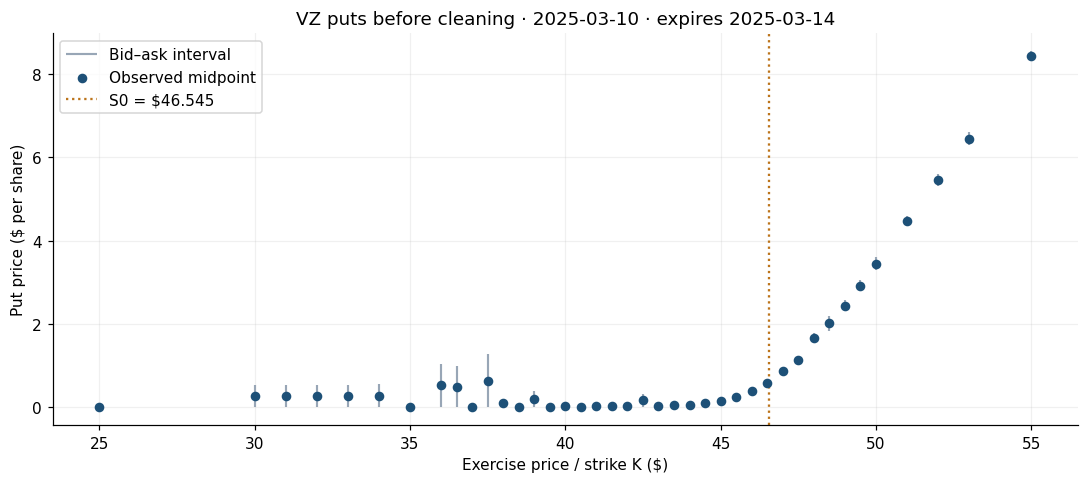

In [15]:
fig_raw, ax = plt.subplots(figsize=(10, 4.5))
plot_raw = chain.loc[np.isfinite(chain[['strike', 'bid', 'ask', 'mid']]).all(axis=1)]
ax.vlines(plot_raw.strike, plot_raw.bid, plot_raw.ask, color='#98a6b6', lw=1.4, label='Bid–ask interval')
ax.scatter(plot_raw.strike, plot_raw.mid, s=28, color='#1d5077', label='Observed midpoint', zorder=3)
ax.axvline(S0, color='#bc741b', ls=':', label=f'S0 = ${S0:.3f}')
ax.set(xlabel='Exercise price / strike K ($)', ylabel='Put price ($ per share)',
       title=f'VZ puts before cleaning · {trade_date.date()} · expires {expiry.date()}')
ax.legend(); fig_raw.tight_layout(); plt.show()

And apply the flags

In [16]:
flags = quality_flags(chain)
unknown_strikes = set(MANUAL_EXCLUSIONS) - set(chain.strike)
if unknown_strikes:
    raise ValueError(f'Manual exclusion strikes absent from chain: {unknown_strikes}')
if any(not isinstance(reason, str) or not reason.strip() for reason in MANUAL_EXCLUSIONS.values()):
    raise ValueError('Every manual exclusion must have a nonempty reason.')
manual_reason = chain.strike.map(MANUAL_EXCLUSIONS).fillna('')
chain['exclusion_reason'] = flags.apply(lambda row: '; '.join(row.index[row]), axis=1)
for idx in chain.index[manual_reason.ne('')]:
    existing = chain.at[idx, 'exclusion_reason']
    chain.at[idx, 'exclusion_reason'] = (existing + '; ' if existing else '') + 'manual: ' + manual_reason.at[idx]
chain['retained'] = chain.exclusion_reason.eq('')
clean = chain.loc[chain.retained].copy()
excluded = chain.loc[~chain.retained].copy()
if clean.empty:
    raise ValueError('No quotes survived. Review your selected date and thresholds.')
if len(clean) < 8:
    warnings.warn('Few retained strikes: estimating a flexible mixture may be unstable.')

audit_columns = ['source_row', 'strike', 'bid', 'ask', 'mid', 'spread', 'relative_spread',
                 'openInterest', 'prtVolume', 'retained', 'exclusion_reason']
audit_columns = [c for c in audit_columns if c in chain]
audit = chain[audit_columns].copy()
rule_counts = flags.sum().rename('Quotes failing rule').to_frame()
rule_counts.loc['manual exclusion'] = int(manual_reason.ne('').sum())
display(rule_counts)
print(f'Retained {len(clean)} of {len(chain)} puts; excluded {len(excluded)}.')
print('Retained strikes:', clean.strike.tolist())
display(audit.round({'mid': 4, 'spread': 4, 'relative_spread': 4}))

,Quotes failing rule
nonfinite strike/bid/ask,0
nonpositive strike,0
negative bid or ask,0
crossed market (ask < bid),0
zero bid,19
midpoint below minimum,11
absolute spread above limit,11
relative spread above limit,21
manual exclusion,0


Retained 17 of 40 puts; excluded 23.
Retained strikes: [43.5, 44.0, 44.5, 45.0, 45.5, 46.0, 46.5, 47.0, 47.5, 48.0, 49.0, 49.5, 50.0, 51.0, 52.0, 53.0, 55.0]


,source_row,strike,bid,ask,mid,spread,relative_spread,openInterest,prtVolume,retained,exclusion_reason
3564,3566,25.0,0.00,0.01,0.005,0.01,2.0000,0,0,False,zero bid; midpoint below minimum; relative spr...
3566,3568,30.0,0.00,0.53,0.265,0.53,2.0000,0,0,False,zero bid; absolute spread above limit; relativ...
3568,3570,31.0,0.00,0.53,0.265,0.53,2.0000,0,0,False,zero bid; absolute spread above limit; relativ...
3570,3572,32.0,0.00,0.54,0.270,0.54,2.0000,0,0,False,zero bid; absolute spread above limit; relativ...
3572,3574,33.0,0.00,0.54,0.270,0.54,2.0000,0,0,False,zero bid; absolute spread above limit; relativ...
3574,3576,34.0,0.00,0.56,0.280,0.56,2.0000,0,0,False,zero bid; absolute spread above limit; relativ...
3576,3578,35.0,0.00,0.02,0.010,0.02,2.0000,1,0,False,zero bid; midpoint below minimum; relative spr...
3578,3580,36.0,0.00,1.05,0.525,1.05,2.0000,62,0,False,zero bid; absolute spread above limit; relativ...
3580,3582,36.5,0.00,0.99,0.495,0.99,2.0000,1,0,False,zero bid; absolute spread above limit; relativ...
3582,3584,37.0,0.00,0.02,0.010,0.02,2.0000,97,0,False,zero bid; midpoint below minimum; relative spr...


Data visualization of the values we discarded and the ones we stayed with

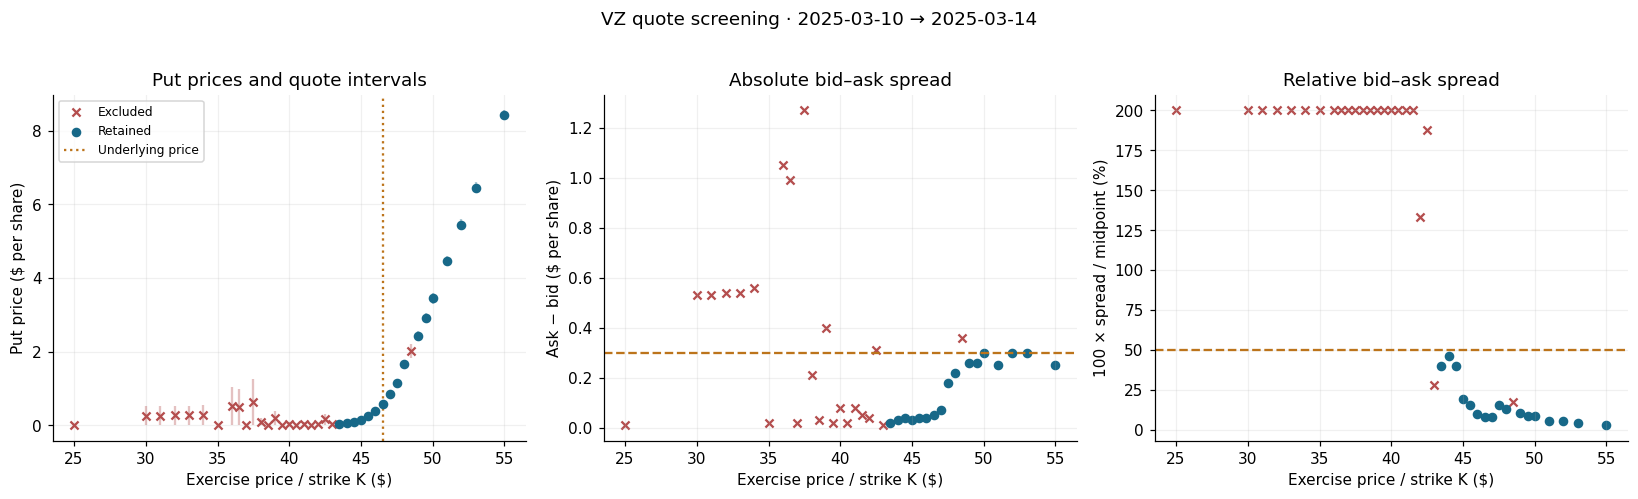

In [17]:
fig_clean, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for keep, label, color, marker in [(False, 'Excluded', '#b44e4e', 'x'),
                                  (True, 'Retained', '#176888', 'o')]:
    d = chain.loc[chain.retained.eq(keep)]
    axes[0].vlines(d.strike, d.bid, d.ask, color=color, alpha=0.35)
    axes[0].scatter(d.strike, d.mid, c=color, marker=marker, s=28, label=label, zorder=3)
    axes[1].scatter(d.strike, d.spread, c=color, marker=marker, s=28)
    axes[2].scatter(d.strike, 100*d.relative_spread, c=color, marker=marker, s=28)
axes[0].axvline(S0, color='#bc741b', ls=':', label='Underlying price')
axes[0].set(title='Put prices and quote intervals', ylabel='Put price ($ per share)')
axes[0].legend(fontsize=8)
axes[1].axhline(MAX_ABS_SPREAD, color='#bc741b', ls='--', label='Absolute cutoff')
axes[1].set(title='Absolute bid–ask spread', ylabel='Ask − bid ($ per share)')
axes[2].axhline(100*MAX_REL_SPREAD, color='#bc741b', ls='--', label='Relative cutoff')
axes[2].set(title='Relative bid–ask spread', ylabel='100 × spread / midpoint (%)')
for ax in axes:
    ax.set_xlabel('Exercise price / strike K ($)')
fig_clean.suptitle(f'VZ quote screening · {trade_date.date()} → {expiry.date()}', y=1.02)
fig_clean.tight_layout(); plt.show()

Just by this graph we can see that more puts were excluded than calls, this could change drastically our results and distributions as it seems it is discarding the tails.

Save puts

In [18]:
calibration_data = clean[['trade_date', 'expiry', 'strike', 'bid', 'ask', 'mid',
                          'spread', 'relative_spread', 'source_row']].copy()
calibration_data['S0'] = S0
calibration_data['T'] = T
calibration_data['r'] = r
K = calibration_data.strike.to_numpy(dtype=float)
C_obs = calibration_data.mid.to_numpy(dtype=float)

metadata = {
    'source_file': CSV_PATH.name, 'source_sha256': file_sha256,
    'trade_date': str(trade_date.date()), 'expiry': str(expiry.date()),
    'calendar_days': calendar_days, 'S0': S0, 'spot_source': '(uBid + uAsk) / 2',
    'T': T, 'time_source': TIME_SOURCE, 'T_calendar': T_calendar, 'T_vendor': T_vendor,
    'r': r, 'rate_note': RATE_NOTE, 'rate_override': RATE_OVERRIDE,
    'dividend_assumption': 'Unresolved: verify schedule and CSV field conventions before fitting',
    'price_source': '(bidPrc + askPrc) / 2',
    'min_mid': MIN_MID, 'max_absolute_spread': MAX_ABS_SPREAD,
    'max_relative_spread': MAX_REL_SPREAD,
    'manual_exclusions': {str(k): v for k, v in MANUAL_EXCLUSIONS.items()},
    'available_puts': len(chain), 'retained_puts': len(clean),
    'strike_min': float(K.min()), 'strike_max': float(K.max()),
}
assert calibration_data.strike.is_unique
assert np.isfinite(calibration_data[['strike','bid','ask','mid','S0','T','r']]).all().all()
assert (calibration_data.ask >= calibration_data.bid - EPS).all()
display(calibration_data.round(6))
if EXPORT_FILES:
    out = Path('part4_outputs')
    out.mkdir(exist_ok=True)
    calibration_data.to_csv(out / 'VZ_part4_clean_puts.csv', index=False)
    audit.to_csv(out / 'VZ_part4_quote_audit.csv', index=False)
    candidates.to_csv(out / 'VZ_part4_candidates.csv', index=False)
    (out / 'VZ_part4_inputs.json').write_text(json.dumps(metadata, indent=2))
    fig_raw.savefig(out / 'VZ_part4_observed_puts.png', dpi=180, bbox_inches='tight')
    fig_clean.savefig(out / 'VZ_part4_screening.png', dpi=180, bbox_inches='tight')
    print('Exported tables, assumptions and plots to', out.resolve())
else:
    print('Exports disabled; all tables and plots remain visible in this notebook.')

,trade_date,expiry,strike,bid,ask,mid,spread,relative_spread,source_row,S0,T,r
3608,2025-03-10,2025-03-14,43.5,0.04,0.06,0.050,0.02,0.400000,3610,46.545,0.010959,0.044504
3610,2025-03-10,2025-03-14,44.0,0.05,0.08,0.065,0.03,0.461538,3612,46.545,0.010959,0.044504
3612,2025-03-10,2025-03-14,44.5,0.08,0.12,0.100,0.04,0.400000,3614,46.545,0.010959,0.044504
3614,2025-03-10,2025-03-14,45.0,0.14,0.17,0.155,0.03,0.193548,3616,46.545,0.010959,0.044504
3616,2025-03-10,2025-03-14,45.5,0.23,0.27,0.250,0.04,0.160000,3618,46.545,0.010959,0.044504
3618,2025-03-10,2025-03-14,46.0,0.37,0.41,0.390,0.04,0.102564,3620,46.545,0.010959,0.044504
3620,2025-03-10,2025-03-14,46.5,0.57,0.62,0.595,0.05,0.084034,3622,46.545,0.010959,0.044504
3622,2025-03-10,2025-03-14,47.0,0.83,0.90,0.865,0.07,0.080925,3624,46.545,0.010959,0.044504
3624,2025-03-10,2025-03-14,47.5,1.05,1.23,1.140,0.18,0.157895,3626,46.545,0.010959,0.044504
3626,2025-03-10,2025-03-14,48.0,1.56,1.78,1.670,0.22,0.131737,3628,46.545,0.010959,0.044504


Exported tables, assumptions and plots to C:\Users\samla\OneDrive\Documentos 1\Documentos\ELAB\Maestría\NYU\Semester 1\Valuation for Financial Engineering\Homework\Mini Project 5\miniProject5\part4_outputs


---
# MOCTRAN PART LOGNORMAL
---

---
## Normal Mixture

For the normal mixture, we first need to define a new function for pricing puts using Bachelier:

$$
P_i = \Beta(K - \mu_i) \Phi(-d) + \Beta \sigma \sqrt{T} \phi(d)  \\
\text{where } \\
d = \frac{\mu_i - K}{\sigma\sqrt{T}} \\
and \\
\Beta = e^{-rT}
$$

And we aslso need to define new functions: `bach_put`, `mix_put` and `optim_fun_put`

In [32]:
from scipy.stats import norm
def bach_put(r, mu, K, sigma, T):

    B = np.exp(-r*T)
    d = (mu-K)/(sigma*np.sqrt(T))

    c_price = B*(K-mu)*norm.cdf(-d) + B*sigma*np.sqrt(T)*norm.pdf(d)

    return c_price

def mix_put(K, theta, r, T):
    mu1, sigma1, mu2, sigma2, w = theta

    call_mix = w* bach_put(r, mu1, K, sigma1, T) + (1-w)*bach_put(r, mu2, K, sigma2, T)
    return call_mix

def optim_fun_put(theta, K, C_obs, r, T):
    C_model = mix_put(K, theta, r, T)
    return np.sum((C_model - C_obs)**2)

Now we read the processed puts just for sanity check

In [33]:
PROJECT_ROOT = Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / 'part4_outputs'

processed_puts = pd.read_csv(PROCESSED_DIR / 'VZ_part4_clean_puts.csv')

processed_puts

,trade_date,expiry,strike,bid,ask,mid,spread,relative_spread,source_row,S0,T,r
0,2025-03-10,2025-03-14,43.5,0.04,0.06,0.050,0.02,0.400000,3610,46.545,0.010959,0.044504
1,2025-03-10,2025-03-14,44.0,0.05,0.08,0.065,0.03,0.461538,3612,46.545,0.010959,0.044504
2,2025-03-10,2025-03-14,44.5,0.08,0.12,0.100,0.04,0.400000,3614,46.545,0.010959,0.044504
3,2025-03-10,2025-03-14,45.0,0.14,0.17,0.155,0.03,0.193548,3616,46.545,0.010959,0.044504
4,2025-03-10,2025-03-14,45.5,0.23,0.27,0.250,0.04,0.160000,3618,46.545,0.010959,0.044504
5,2025-03-10,2025-03-14,46.0,0.37,0.41,0.390,0.04,0.102564,3620,46.545,0.010959,0.044504
6,2025-03-10,2025-03-14,46.5,0.57,0.62,0.595,0.05,0.084034,3622,46.545,0.010959,0.044504
7,2025-03-10,2025-03-14,47.0,0.83,0.90,0.865,0.07,0.080925,3624,46.545,0.010959,0.044504
8,2025-03-10,2025-03-14,47.5,1.05,1.23,1.140,0.18,0.157895,3626,46.545,0.010959,0.044504
9,2025-03-10,2025-03-14,48.0,1.56,1.78,1.670,0.22,0.131737,3628,46.545,0.010959,0.044504


And now we start defining our new variables:

In [34]:
# define desired variables
K_p = processed_puts['strike'].to_numpy()
P_obs = processed_puts['mid'].to_numpy()

S_0_p = processed_puts['S0'].iloc[0]
T_p = processed_puts['T'].iloc[0]
r_p = processed_puts['r'].iloc[0]

And we optimize following the next random initial parameters for the puts

- $\mu_1 \sim Unif(S_0 - 2, S_0)$
- $\sigma_1 \sim Unif(0.3, 2)$
- $\mu_2 \sim Unif(S_0, S_0+2)$
- $\sigma_2 \sim Unif(0.3, 2)$
- $w \sim Unif(0.2,0.8)$

With the following bounds:
- $\sigma_1 > 0$
- $\sigma_2 > 0$
- $0 \leq w \leq 1$


In [35]:
from scipy.optimize import minimize
rand_seed = 123

np.random.seed(rand_seed)
theta_ini_put = (
    np.random.uniform(S_0_p - 2, S_0_p),
    np.random.uniform(0.3, 2),
    np.random.uniform(S_0_p, S_0_p + 2),
    np.random.uniform(0.3, 2),
    np.random.uniform(0.2, 0.8)
)

bounds = [
    (None, None),  # mu1
    (1e-6, None),  # sigma1 > 0
    (None, None),  # mu2
    (1e-6, None),  # sigma2 > 0
    (0, 1)         # 0 <= w <= 1
]
res_put = minimize(optim_fun_put, theta_ini_put, args= (K_p, P_obs, r_p, T_p), method="L-BFGS-B", bounds=bounds)


In [36]:
print("Success:", res_put.success)
print("Message:", res_put.message)
print("Parameters:", res_put.x)
print("Objective:", res_put.fun)

Success: True
Message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
Parameters: [44.11049747  2.7157649  46.5616265  15.1608689   0.        ]
Objective: 0.018711411440428843


The results imply that for the distribution on puts there we could have only one Normal distribution, however, we would like to check this result by making more than one initial guess. This is to prevent the possibility of the opitmizer converging in a local minimum rather than the global one.

In [53]:
results = []

rng = np.random.default_rng(123)

for i in range(100):
    theta0 = (
        rng.uniform(S_0_p - 2, S_0_p),
        rng.uniform(0.3, 20),
        rng.uniform(S_0_p, S_0_p + 2),
        rng.uniform(0.3, 20),
        rng.uniform(0.1, 0.9)
    )

    result = minimize(
        optim_fun_put,
        theta0,
        args=(K_p, P_obs, r_p, T_p),
        method="L-BFGS-B",
        bounds=bounds
    )

    if result.success:
        results.append(result)

best_p = min(results, key=lambda result: result.fun)

print("Best parameters:", best_p.x)
print("Best objective:", best_p.fun)
print("Successful optimizations:", len(results))

Best parameters: [3.90535720e+01 1.93495456e+01 4.66238233e+01 1.41663030e+01
 8.96505426e-03]
Best objective: 0.014721857974407393
Successful optimizations: 100


In [54]:
mu1_p, sigma1_p, mu2_p, sigma2_p, w_p = best_p.x

P_model = mix_put(K_p, best_p.x, r_p, T_p)

rmse_p = np.sqrt(np.mean((P_model - P_obs)**2))

print("RMSE:", rmse_p)
print("Mixture mean:", w_p*mu1_p + (1-w_p)*mu2_p)

RMSE: 0.02942773599095547
Mixture mean: 46.555955621790915


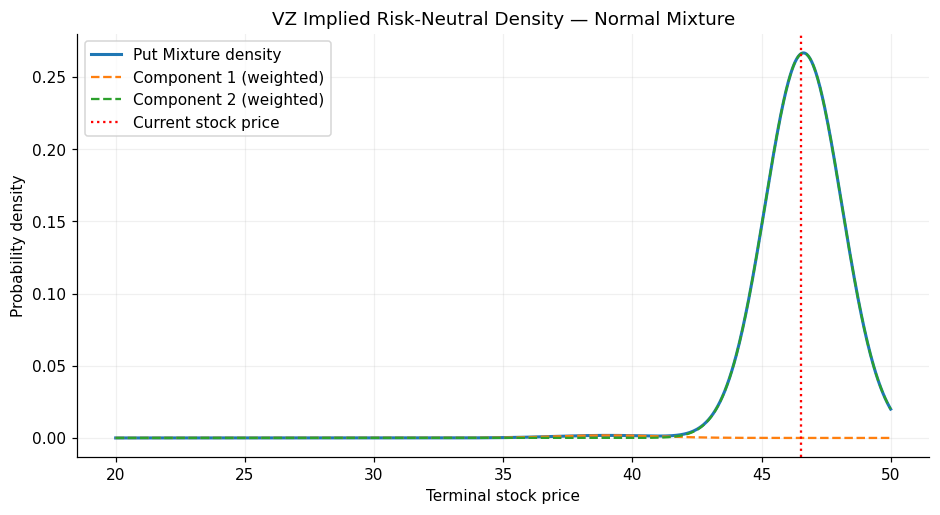

In [55]:
sigma_T1_p = sigma1_p*np.sqrt(T_p)
sigma_T2_p = sigma2_p*np.sqrt(T_p)

s = np.linspace(20, 50, 1000)

density1_p = w_p * norm.pdf(s, mu1_p, sigma_T1_p)
density2_p = (1-w_p) * norm.pdf(s, mu2_p, sigma_T2_p)

density_mix_p = density1_p + density2_p

plt.figure(figsize=(10, 5))

plt.plot(s, density_mix_p, label="Put Mixture density", linewidth=2)
plt.plot(s, density1_p, "--", label="Component 1 (weighted)")
plt.plot(s, density2_p, "--", label="Component 2 (weighted)")

plt.axvline(S_0_p, color="red", linestyle=":", label="Current stock price")

plt.xlabel("Terminal stock price")
plt.ylabel("Probability density")
plt.title("VZ Implied Risk-Neutral Density — Normal Mixture")
plt.legend()
plt.grid(True)
plt.show()

We can now add this to the previuos table of comparison

In [50]:


# Mean
mean_mix_p = w_p * mu1_p + (1 - w_p) * mu2_p

# Variance and standard deviation
var_mix_p = (
    w_p * (sigma_T1_p**2 + (mu1_p - mean_mix_p)**2)
    + (1-w_p) * (sigma_T2_p**2 + (mu2_p - mean_mix_p)**2)
)

std_mix_p = np.sqrt(var_mix_p)

# Third central moment
m3_p = (
    w_p * ((mu1_p - mean_mix_p)**3
         + 3 * (mu1_p - mean_mix_p) * sigma_T1_p**2)
    + (1-w_p) * ((mu2_p - mean_mix_p)**3
               + 3 * (mu2_p - mean_mix_p) * sigma_T2_p**2)
)

skew_mix_p = m3_p / std_mix_p**3

# Probability of a 5% decline
threshold_p = 0.95 * S_0_p

prob_decline_mix_p = (
    w_p * norm.cdf(threshold_p, loc=mu1_p, scale=sigma_T1_p)
    + (1-w_p) * norm.cdf(threshold_p, loc=mu2_p, scale=sigma_T2_p)
)

# RMSE
rmse_mix_p = np.sqrt(np.mean((P_model - P_obs)**2))

columns = ['Measure', 'Lognormal (Puts)', 'Normal Mixture (Puts)']
measure = ['Mean terminal stock price', 'Skeweness', 'Probability of a 5% price decline', 'Root mean squared pricing error ']

data_mix_p = [mean_mix_p, skew_mix_p, prob_decline_mix_p, rmse_mix_p]
table_report_p = pd.DataFrame(columns = columns, index = list(range(len(measure))))
table_report_p['Measure'] = measure
table_report_p['Normal Mixture (Puts)'] = data_mix_p

table_report_p

,Measure,Lognormal (Puts),Normal Mixture (Puts)
0,Mean terminal stock price,NaN,46.555956
1,Skeweness,NaN,-0.926656
2,Probability of a 5% price decline,NaN,0.060802
3,Root mean squared pricing error,NaN,0.033176


it is really similar to the call mix, the first normal has the least weight while the second has the most weight. However, the put density is slightly more skewed and it's RMSE is higher than the call. This can also be beacuse we had less processed prices for put options than for call options